## 1. Setup and configuration

All settings live in this one cell so every experiment is run under the same conditions.

In [2]:
import math
import os
import pickle
import time
import zipfile

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from torchvision import datasets

# ---------------- Experiment settings ----------------
SEED = 0                  # fixes the data split, the weight initialization, and the batch order
NUM_DIAGNOSTIC_SAMPLES = 256   # size of the fixed batch used for every measurement
DIAGNOSE_EVERY_N_STEPS = 1     # 1 = measure after every SGD step
NUM_CLASSES = {"mnist": 10, "cifar10": 10, "imagenet32": 1000}


# ---------------- Run settings ----------------
RERUN = False             # False: reuse saved results in RESULTS_DIR if they exist
USE_CUDA_GRAPHS = True    # GPU only: record each step once and replay it (much faster; see section 6.2)
SAVE_TO_GOOGLE_DRIVE = False   # Colab: keep results in Drive so they survive a disconnect
RESULTS_DIR = "diagnostic_results"
DATA_DIR = "data"
#TASKS_TO_RUN = ["mnist", "cifar10", "imagenet32"]
TASKS_TO_RUN = ["mnist"]

# ---------------- Device ----------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Newer GPUs silently use a reduced-precision format (TF32) for float32 matrix multiplies.
# Turn it off so measurements match a CPU run.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

os.makedirs(RESULTS_DIR, exist_ok=True)

print("PyTorch", torch.__version__)
if DEVICE.type == "cuda":
    print("Device: GPU,", torch.cuda.get_device_name(0))
else:
    print("Device: CPU")
    print("WARNING: no GPU found. On Colab: Runtime -> Change runtime type -> GPU, then run again.")

PyTorch 2.13.0
Device: GPU, NVIDIA RTX 5000 Ada Generation Laptop GPU


In [3]:
# For each task: Hugging Face dataset name, image column, train split, test split.
SOURCES = {
    "mnist":      ("ylecun/mnist",                     "image", "train", "test"),
    "cifar10":    ("uoft-cs/cifar10",                  "img",   "train", "test"),
    "imagenet32": ("benjamin-paine/imagenet-1k-32x32", "image", "train", "validation"),
}

def save_split(split, image_column, mode, folder, name):
    """Write one Hugging Face split to X_<name>.npy (N, C, H, W) and y_<name>.npy.

    The images are written straight into a file on disk, 10,000 at a time, so
    even ImageNet (about 4 GB) never has to fit in memory all at once.
    """
    n = len(split)
    height, width = np.asarray(split[0][image_column]).shape[:2]
    channels = 1 if mode == "L" else 3
    X = np.lib.format.open_memmap(os.path.join(folder, f"X_{name}.npy"), mode="w+",
                                  dtype=np.uint8, shape=(n, channels, height, width))
    y = np.empty(n, dtype=np.int64)
    for start in range(0, n, 10_000):
        chunk = split[start:start + 10_000]
        # mode is "L" (grayscale) or "RGB"; convert() fixes any odd image formats.
        images = np.stack([np.asarray(img.convert(mode)) for img in chunk[image_column]])
        stop = start + len(images)
        X[start:stop] = images[:, None] if mode == "L" else images.transpose(0, 3, 1, 2)
        y[start:stop] = chunk["label"]
        print(f"  {name}: {stop:,} / {n:,} images", end="\r")
    print()
    X.flush()
    np.save(os.path.join(folder, f"y_{name}.npy"), y)

def load_task(task):
    """Return X_train, y_train, X_test, y_test, downloading only if there is no saved copy.

    The arrays are memory-mapped: they are read from disk as they are used
    instead of all being loaded into RAM up front.
    """
    folder = os.path.join(DATA_DIR, task)
    old_file = os.path.join(DATA_DIR, f"{task}.npz")   # saved by an earlier version of this notebook

    if not os.path.isdir(folder) and os.path.exists(old_file):
        # Unpack the earlier single-file copy into the folder format; no download needed.
        print(f"{task}: unpacking {old_file} (one time only; you can delete it afterwards)")
        temp_folder = folder + ".partial"
        os.makedirs(temp_folder, exist_ok=True)
        # An .npz file is a zip of .npy files, so extracting it streams them to disk
        # without loading the arrays into memory.
        with zipfile.ZipFile(old_file) as old:
            old.extractall(temp_folder)
        os.replace(temp_folder, folder)

    if not os.path.isdir(folder):                    # no saved copy yet: download it
        from datasets import load_dataset
        name, image_column, train_split, test_split = SOURCES[task]
        mode = "L" if task == "mnist" else "RGB"
        print(f"{task}: getting {name} from Hugging Face (first run only; reuses its download cache if present)")

        # Write into a temporary folder, then rename it. An interrupted run then
        # never leaves a half-written folder that looks like a finished one.
        temp_folder = folder + ".partial"
        os.makedirs(temp_folder, exist_ok=True)
        save_split(load_dataset(name, split=train_split), image_column, mode, temp_folder, "train")
        save_split(load_dataset(name, split=test_split), image_column, mode, temp_folder, "test")
        os.replace(temp_folder, folder)

    # mmap_mode="c" (copy-on-write): read from disk on demand, and any changes
    # your code makes to the arrays stay in memory and never touch the files.
    return tuple(np.load(os.path.join(folder, f"{part}.npy"), mmap_mode="c")
                 for part in ["X_train", "y_train", "X_test", "y_test"])



In [4]:
TASK = TASKS_TO_RUN[0]

all_train_images, all_train_labels, test_images, test_labels = load_task(TASK)

# ---- Split the 60k training images into 50k train / 10k validation ----
shuffled_indices = torch.randperm(len(all_train_images), generator=torch.Generator().manual_seed(SEED))
validation_indices = shuffled_indices[:10_000]
train_indices = shuffled_indices[10_000:]

X_train, y_train = all_train_images[train_indices], all_train_labels[train_indices]
X_val, y_val = all_train_images[validation_indices], all_train_labels[validation_indices]
X_test, y_test = test_images, test_labels


pixel_mean = all_train_images.mean()
pixel_std = all_train_images.std()


# ---- The fixed diagnostic batch ----
X_diag = X_val[:NUM_DIAGNOSTIC_SAMPLES]
y_diag = y_val[:NUM_DIAGNOSTIC_SAMPLES]

#STEPS_PER_EPOCH = len(X_train) // BATCH_SIZE   # the last partial batch is dropped

print(f"train:       {len(y_train):6d} images")
print(f"validation:  {len(y_val):6d} images")
print(f"test:        {len(y_test):6d} images")
print(f"diagnostic:  {len(y_diag):6d} images (first {NUM_DIAGNOSTIC_SAMPLES} validation images)")
print(f"pixel mean {pixel_mean:.4f}, std {pixel_std:.4f}; "
      f"training input variance is now {X_train.var():.3f}")
#print(f"{STEPS_PER_EPOCH} SGD steps per epoch")

train:        50000 images
validation:   10000 images
test:         10000 images
diagnostic:     256 images (first 256 validation images)
pixel mean 33.3184, std 78.5675; training input variance is now 6171.017


The classes are nearly balanced, so always guessing the majority class gets about 51%. Any network that learns something must beat that.

Every network sees the training images in the **same shuffled order**: the shuffle for each epoch is seeded by the epoch number alone. Differences between networks therefore come from the architecture, not from batch order.

In [5]:
def training_batches(epoch):
    """Yield (images, labels) mini-batches for one epoch, in an order fixed by the epoch number."""
    order = torch.randperm(len(X_train), generator=torch.Generator().manual_seed(1000 + epoch))
    order = order.to(DEVICE)
    for step in range(STEPS_PER_EPOCH):
        batch_indices = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
        yield X_train[batch_indices], y_train[batch_indices]

## 3. The model


In [20]:
import sys
import subprocess
import importlib
from dotenv import load_dotenv
from IPython import get_ipython

PACKAGE_URL = "git+https://github.com/cchamb-gh/AI4200-imagenet32x32-baseline-model.git"
IMPORT_NAME = "residual_mlp_baseline"

clays_laptop = os.getenv("CLAYS_LAPTOP", False).lower() in ("true", "1", "t") # read from my .env 

if not clays_laptop:
    print("HPC mode: installing packages")
    # Run pip commands directly using the active Python executable
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", 
        "--force-reinstall", "--no-deps", PACKAGE_URL
    ])
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "datasets"
    ])
    
    # Import the newly installed package
    student = importlib.import_module(IMPORT_NAME)
    print(f"Loaded installed package: {student.__name__}")

else:
    print("Local dev mode (Clay's Laptop): Loading from src/")
    
    # Configure autoreload programmatically
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic("load_ext", "autoreload")
        ip.run_line_magic("autoreload", "2")
    
    # Append local src directory to path
    if "src" not in sys.path:
        sys.path.append("src")
        
    # Import dynamically from local src directory
    if IMPORT_NAME in sys.modules:
        student = importlib.reload(sys.modules[IMPORT_NAME])
    else:
        student = importlib.import_module(IMPORT_NAME)
    print(f"Loaded local module: {student.__name__}")


Local dev mode (Clay's Laptop): Loading from src/
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loaded local module: residual_mlp_baseline


In [7]:
model = student.train(TASK, X_train, y_train, seed=SEED, device=DEVICE)
NUM_BLOCKS = len(model.blocks)
model



epoch 1: train loss 1.3973
epoch 2: train loss 0.5183
epoch 3: train loss 0.2980
epoch 4: train loss 0.2019
epoch 5: train loss 0.1474
epoch 6: train loss 0.1270
epoch 7: train loss 0.1160
epoch 8: train loss 0.0887
epoch 9: train loss 0.1460
epoch 10: train loss 0.0686


ResidualMLP(
  (input_layer): Linear(in_features=784, out_features=128, bias=True)
  (blocks): ModuleList(
    (0-29): 30 x Block(
      (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (fc1): Linear(in_features=128, out_features=256, bias=True)
      (fc2): Linear(in_features=256, out_features=128, bias=True)
    )
  )
  (head_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head_fc1): Linear(in_features=128, out_features=256, bias=True)
  (head_fc2): Linear(in_features=256, out_features=10, bias=True)
)

## 4. Predictions from the variance argument

Let $v_l$ be the variance of the stream after block $l$. With the initialization above, a branch outputs the same variance as its input (times $\alpha^2$ when scaled). The branch output is uncorrelated with the stream at initialization, so variances add.

**Without normalization** the branch's input is the stream itself, so the branch adds $\alpha^2 v_l$. Variance **multiplies** from block to block:

$$v_{l+1} = v_l + \alpha^2 v_l = (1 + \alpha^2)\, v_l \quad\Rightarrow\quad v_l = v_0\,(1+\alpha^2)^l$$

- `control`, $\alpha = 1$: $v_l = v_0 \cdot 2^l$.
- `scaled`, $\alpha^2 = 1/L$: $v_L = v_0 (1 + 1/L)^L \approx e\, v_0$. In general the product stays bounded exactly when $\sum_l \alpha_l^2$ is finite, because $\prod_l (1+\alpha_l^2) \le \exp(\sum_l \alpha_l^2)$.

**With pre-norm** the branch's input always has variance 1, so the branch always adds 1, however large $v_l$ is. Variance **adds**:

$$v_{l+1} = v_l + 1 \quad\Rightarrow\quad v_l = v_0 + l$$

The final norm then rescales $v_L \approx 201$ back to 1 before the output layer.

In [35]:
def predicted_stream_variance(network_name, v0, num_blocks=NUM_BLOCKS):
    """Predicted variance of x_0, x_1, ..., x_L at initialization. Returns an array of length L + 1."""
    block_index = np.arange(num_blocks + 1, dtype=np.float64)

    if network_name == "control":
        # Multiplicative: each block doubles the variance.
        return v0 * 2.0 ** block_index
    if network_name == "scaled":
        # Multiplicative, but each block only multiplies by (1 + 1/L).
        alpha_squared = 1.0 / num_blocks
        return v0 * (1.0 + alpha_squared) ** block_index
    if network_name in ("batchnorm", "layernorm"):
        # Additive: each block adds variance 1.
        return v0 + block_index
    raise ValueError(network_name)


# v0: the measured variance of the stream after the input layer (the same for every network).
with torch.no_grad():
    #v0 = build_network("layernorm").input_layer(X_diag).double().var().item()
    model = student.create_model_for_task(TASK)
    v0 = model.input_layer(X_diag).double().var().item()
print(f"v0 = {v0:.3f}\n")
print(f"{'network':10s} {'predicted variance at block L/2':>32s} {'at block L':>14s}")
for name in NETWORK_CLASSES:
    predicted = predicted_stream_variance(name, v0)
    print(f"{name:10s} {predicted[NUM_BLOCKS // 2]:32.4g} {predicted[-1]:14.4g}")

TypeError: linear(): argument 'input' (position 1) must be Tensor, not numpy.ndarray

## 5. Diagnostics

Each measure is computed at every depth $l = 0, \dots, L$ on the fixed diagnostic batch. The stream is stacked into one tensor of shape `[L+1, samples, width]`, so each measure is a few tensor operations over all depths at once.

**Forward variance.** The variance of all entries of $x_l$. Computed in float64: the control network's values reach $10^{29}$, and their squares would overflow float32.

**Correlation across samples.** Take two different images $i$ and $j$. At depth $l$ each is represented by a vector $x_l^{(i)}, x_l^{(j)} \in \mathbb{R}^{128}$. Their Pearson correlation is the cosine of the angle between the two vectors after each is centered (its own mean feature value subtracted). The measure is the average over all pairs $i \ne j$.
- The input images are already somewhat similar, so this starts around 0.3.
- If it climbs toward **1**, every image is being mapped to the same direction. The network can no longer tell its inputs apart, and the output layer has nothing to work with (*rank collapse*).

**Gradient RMS.** The root-mean-square of a gradient: $\sqrt{\text{mean}(g^2)}$.
- `stream_grad_rms[l]`: gradient of the loss with respect to the stream $x_l$. This is the backward signal as it passes block $l$.
- `linear1_grad_rms[l]`, `linear2_grad_rms[l]`: gradients of block $l$'s two weight matrices. These set how much each block's weights move per SGD step.

Healthy gradients have a similar size at every depth. If they shrink or grow by orders of magnitude across depth, some blocks barely learn and others take huge steps.

**Why these functions avoid `.item()`.** Calling `.item()` or `.cpu()` on a GPU tensor makes the CPU wait for the GPU to finish. The functions below return GPU tensors and never wait, so they can run inside the CUDA graph of section 6.2. Results are copied to the CPU once, at the end of training.

In [22]:
def measure_forward_variance(stream):
    """stream: [L+1, samples, width].  Returns [L+1]: variance of all entries at each depth."""
    stream = stream.double()
    per_depth = stream.flatten(start_dim=1)            # [L+1, samples * width]
    return per_depth.var(dim=1, unbiased=False)


def measure_sample_correlation(stream):
    """stream: [L+1, samples, width].  Returns [L+1]: mean Pearson correlation between different samples."""
    vectors = stream.double()
    # Center each sample's vector over its own features, then scale it to length 1.
    vectors = vectors - vectors.mean(dim=2, keepdim=True)
    vectors = vectors / vectors.norm(dim=2, keepdim=True).clamp_min(1e-300)
    # For unit vectors, the dot product IS the correlation. One [samples x samples] matrix per depth.
    # (The vectors are now length 1, so float32 is precise enough and much faster on a GPU.)
    vectors = vectors.float()
    correlation_matrices = torch.bmm(vectors, vectors.transpose(1, 2))      # [L+1, samples, samples]
    # Average the off-diagonal entries (the diagonal is each sample with itself, always 1).
    num_samples = vectors.shape[1]
    total = correlation_matrices.sum(dim=(1, 2))
    diagonal = correlation_matrices.diagonal(dim1=1, dim2=2).sum(dim=1)
    return ((total - diagonal) / (num_samples * (num_samples - 1))).double()


def measure_rms(stacked_tensors):
    """stacked_tensors: [depth, ...].  Returns [depth]: root-mean-square at each depth (in float64)."""
    squared = stacked_tensors.double() ** 2
    return squared.flatten(start_dim=1).mean(dim=1).sqrt()


def batchnorm_running_buffers(network):
    """The running mean/variance (and step counter) of every BatchNorm layer in the network."""
    buffers = []
    for module in network.modules():
        if isinstance(module, nn.BatchNorm1d):
            buffers += [module.running_mean, module.running_var, module.num_batches_tracked]
    return buffers


def compute_diagnostics(network, images=None, labels=None):
    """All measurements on one batch. Returns a dict of tensors on the device (no GPU->CPU waits).

    The network is run in training mode. For BatchNorm this means each BN layer normalizes with the
    statistics of this batch, exactly as it does when computing training gradients. (In eval mode
    BN would use its running averages instead; at initialization those are still mean 0, variance 1,
    so eval mode would measure a different network.)
    """
    images = X_diag if images is None else images
    labels = y_diag if labels is None else labels

    images = torch.as_tensor(images).to(DEVICE)
    labels = torch.as_tensor(labels).to(DEVICE)

    # Running a BatchNorm layer in training mode updates its running averages. Save them now and
    # restore them afterwards, so that measuring never changes the network.
    running_buffers = batchnorm_running_buffers(network)
    saved_buffers = [buffer.clone() for buffer in running_buffers]
    network.train()

    # Forward pass that also returns the stream [x_0, ..., x_L].
    logits, stream = network(student.prepare(images), return_stream=True)
    loss = F.binary_cross_entropy_with_logits(logits, labels)

    # Gradients of the loss with respect to every x_l and every block's two weight matrices.
    # torch.autograd.grad returns them directly and does not touch the parameters' .grad fields,
    # so it cannot interfere with training.
    linear1_weights = [block.linear1.weight for block in network.blocks]
    linear2_weights = [block.linear2.weight for block in network.blocks]
    gradients = torch.autograd.grad(loss, stream + linear1_weights + linear2_weights)
    num_blocks = len(network.blocks)
    stream_gradients = gradients[:num_blocks + 1]
    linear1_gradients = gradients[num_blocks + 1:2 * num_blocks + 1]
    linear2_gradients = gradients[2 * num_blocks + 1:]

    with torch.no_grad():
        stacked_stream = torch.stack(stream)                     # [L+1, samples, width]
        results = {
            "loss": loss.detach().double(),
            "stream_variance": measure_forward_variance(stacked_stream),
            "sample_correlation": measure_sample_correlation(stacked_stream),
            "stream_grad_rms": measure_rms(torch.stack(stream_gradients)),
            "linear1_grad_rms": measure_rms(torch.stack(linear1_gradients)),
            "linear2_grad_rms": measure_rms(torch.stack(linear2_gradients)),
        }
        for buffer, saved in zip(running_buffers, saved_buffers):
            buffer.copy_(saved)
    return results

A quick check on a freshly built `layernorm` network: the stream variance at the last block should be near the prediction $v_0 + 200 \approx 201$.

In [15]:
model
next(model.parameters()).device

device(type='cuda', index=0)

In [24]:
measured = compute_diagnostics(model)
measured = {key: value.cpu().numpy() for key, value in measured.items()}

print(f"loss on the diagnostic batch at init: {measured['loss']:.4f}")
for depth in [0, NUM_BLOCKS // 2, NUM_BLOCKS]:
    print(f"x_{depth:<3d}  variance {measured['stream_variance'][depth]:8.2f}"
          f"   correlation {measured['sample_correlation'][depth]:.3f}"
          f"   stream gradient RMS {measured['stream_grad_rms'][depth]:.2e}")

ValueError: Target size (torch.Size([256])) must be the same as input size (torch.Size([256, 10]))

## 6. Training

### 6.1 One SGD step

This is the whole training algorithm: forward pass, binary cross-entropy loss, backward pass, SGD update. Plain SGD means each weight moves by `-LEARNING_RATE × gradient`, with no momentum and no weight decay.

**Learning rate.** A short sweep (200 steps at each of 0.003, 0.01, 0.03, 0.1): `batchnorm` and `layernorm` trained at every rate; `scaled` diverged (the loss became NaN) at 0.1 and trained at 0.05 and below. `0.03` leaves a safety margin for all three while still training quickly.

In [ ]:
def sgd_step(network, optimizer, images, labels):
    """One SGD step. Returns the batch loss as a tensor (not a Python float, to avoid a GPU->CPU wait).

    The caller is responsible for clearing the old gradients before this is called.
    """
    logits = network(images)
    loss = F.binary_cross_entropy_with_logits(logits, labels)
    loss.backward()          # fills parameter.grad for every parameter
    optimizer.step()         # parameter <- parameter - learning_rate * parameter.grad
    return loss.detach()

### 6.2 Making it fast on a GPU: CUDA graphs

*This section only affects speed. The math is exactly `sgd_step` and `compute_diagnostics` above.*

One SGD step on this network is a chain of roughly 4,000 small GPU operations: each of the 200 blocks runs a handful of operations on 128×128 matrices, forward and backward. Each operation has to be launched from Python by the CPU, and for matrices this small, **launching an operation takes longer than the GPU needs to compute it**. Run naively, the GPU sits idle most of the time, waiting for the next launch.

A **CUDA graph** fixes this. PyTorch records every GPU operation of one step once, then replays the whole recording with a single launch. Replays have two constraints:

- **Fixed memory.** Every replay reads from and writes to the same tensors. Each new batch is therefore *copied into* fixed input tensors before the replay, and results are read from fixed output tensors afterwards.
- **No CPU decisions.** Nothing in the recorded step may wait for the GPU (`.item()`, `print` of a tensor, Python `if` on a tensor value). That is why `sgd_step` and `compute_diagnostics` never do this.

`StepRunner` records two graphs: one for the training step, one for the diagnostics. On a CPU, or if recording fails, it simply calls the two functions directly, and the results are the same.

In [ ]:
class StepRunner:
    """Runs SGD steps and diagnostic measurements for one network, using CUDA graphs on a GPU."""

    def __init__(self, network, learning_rate):
        self.network = network
        self.optimizer = torch.optim.SGD(network.parameters(), lr=learning_rate)

        # Fixed input tensors. Every batch is copied into these before a step.
        self.batch_images = torch.zeros(BATCH_SIZE, 784, device=DEVICE)
        self.batch_labels = torch.zeros(BATCH_SIZE, device=DEVICE)

        self.use_graphs = USE_CUDA_GRAPHS and DEVICE.type == "cuda"
        if self.use_graphs:
            try:
                self._record_graphs()
            except Exception as error:
                print(f"  Could not record CUDA graphs ({type(error).__name__}: {error}). "
                      "Falling back to the plain loop.")
                self.use_graphs = False
                torch.cuda.synchronize()

    def _record_graphs(self):
        network, optimizer = self.network, self.optimizer
        network.train()

        # Recording requires a few warm-up runs first, and warm-up SGD steps change the weights.
        # Save every parameter and buffer so the network can be put back exactly as it was.
        all_state = list(network.parameters()) + list(network.buffers())
        saved_state = [tensor.detach().clone() for tensor in all_state]

        self.batch_images.copy_(X_train[:BATCH_SIZE])
        self.batch_labels.copy_(y_train[:BATCH_SIZE])

        # Warm-up on a side stream (required by PyTorch before recording).
        side_stream = torch.cuda.Stream()
        side_stream.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(side_stream):
            for _ in range(3):
                optimizer.zero_grad(set_to_none=True)
                sgd_step(network, optimizer, self.batch_images, self.batch_labels)
                compute_diagnostics(network)
        torch.cuda.current_stream().wait_stream(side_stream)

        # Record the training step. Gradients are cleared once here; inside the graph, each replay
        # writes fresh gradients into the same memory rather than adding to old ones.
        optimizer.zero_grad(set_to_none=True)
        self.train_graph = torch.cuda.CUDAGraph()
        with torch.cuda.graph(self.train_graph):
            self.train_graph_loss = sgd_step(network, optimizer, self.batch_images, self.batch_labels)

        # Record the diagnostics.
        self.diagnostic_graph = torch.cuda.CUDAGraph()
        with torch.cuda.graph(self.diagnostic_graph):
            self.diagnostic_graph_results = compute_diagnostics(network)

        # Recording does not run anything, but the warm-up did. Undo it.
        with torch.no_grad():
            for tensor, saved in zip(all_state, saved_state):
                tensor.copy_(saved)
        torch.cuda.synchronize()

    def train_step(self, images, labels):
        """One SGD step on this batch. Returns the loss tensor (overwritten by the next step: copy it)."""
        self.batch_images.copy_(images)
        self.batch_labels.copy_(labels)
        if self.use_graphs:
            self.train_graph.replay()
            return self.train_graph_loss
        self.optimizer.zero_grad(set_to_none=True)
        return sgd_step(self.network, self.optimizer, self.batch_images, self.batch_labels)

    def diagnostics(self):
        """Measure the network on the diagnostic batch. Returns a dict of tensors (copy them)."""
        if self.use_graphs:
            self.diagnostic_graph.replay()
            return self.diagnostic_graph_results
        return compute_diagnostics(self.network)

### 6.3 The training loop

For each network:

1. Measure at initialization (step 0).
2. For each of the 5 epochs, for each batch: take one SGD step, record its loss, and measure every `DIAGNOSE_EVERY_N_STEPS` steps.
3. At the end of each epoch, compute validation accuracy.
4. After the last epoch, compute test accuracy once.

**Storing results.** All losses and measurements go into tensors allocated on the device before training starts (`history`), and are copied to the CPU once at the end. Every 10 steps the loop checks whether the loss has become infinite or NaN; if so, the network has **diverged**, and training stops.

**Accuracy.** Evaluation uses `network.eval()`. For BatchNorm this switches from batch statistics to the running averages collected during training. For LayerNorm and the unnormalized networks it changes nothing.

In [ ]:
@torch.no_grad()
def accuracy(network, images, labels):
    """Fraction of images whose predicted class (logit > 0 means 'digit > 4') matches the label."""
    network.eval()
    predictions = (network(images) > 0).float()
    fraction_correct = (predictions == labels).float().mean().item()
    network.train()
    return fraction_correct


def train_network(name, network, learning_rate=LEARNING_RATE, num_epochs=NUM_EPOCHS,
                  diagnose_every=DIAGNOSE_EVERY_N_STEPS):
    """Train one network with SGD, measuring it throughout. Returns a dict of numpy arrays and numbers."""
    runner = StepRunner(network, learning_rate)
    total_steps = num_epochs * STEPS_PER_EPOCH
    max_records = total_steps // diagnose_every + 1
    num_blocks = len(network.blocks)

    # ---- Pre-allocated storage on the device (NaN = "not recorded") ----
    def empty(*shape):
        return torch.full(shape, float("nan"), dtype=torch.float64, device=DEVICE)

    train_loss = empty(total_steps)
    history = {
        "loss": empty(max_records),
        "stream_variance": empty(max_records, num_blocks + 1),
        "sample_correlation": empty(max_records, num_blocks + 1),
        "stream_grad_rms": empty(max_records, num_blocks + 1),
        "linear1_grad_rms": empty(max_records, num_blocks),
        "linear2_grad_rms": empty(max_records, num_blocks),
    }
    recorded_steps = []

    def record_diagnostics(step):
        measurements = runner.diagnostics()
        row = len(recorded_steps)
        for key in history:
            history[key][row].copy_(measurements[key])
        recorded_steps.append(step)

    # ---- Training ----
    result = {"name": name, "learning_rate": learning_rate, "used_cuda_graphs": runner.use_graphs,
              "epoch_end_steps": [], "validation_accuracy": [], "diverged_at_step": None}
    record_diagnostics(step=0)
    step = 0
    start_time = time.time()

    for epoch in range(num_epochs):
        for images, labels in training_batches(epoch):
            train_loss[step].copy_(runner.train_step(images, labels))
            step += 1

            if step % diagnose_every == 0:
                record_diagnostics(step)

            # Divergence check (this does wait for the GPU, so only do it every 10 steps).
            if step % 10 == 0 or step < 10:
                bad_steps = torch.nonzero(~torch.isfinite(train_loss[:step]))
                if len(bad_steps) > 0:
                    result["diverged_at_step"] = int(bad_steps[0]) + 1
                    break

        if result["diverged_at_step"] is not None:
            print(f"  {name}: loss became non-finite at step {result['diverged_at_step']}; stopping.")
            break

        result["epoch_end_steps"].append(step)
        result["validation_accuracy"].append(accuracy(network, X_val, y_val))
        elapsed = time.time() - start_time
        print(f"  {name}: epoch {epoch + 1}"
              f"   mean train loss (last 50 steps) {train_loss[step - 50:step].mean().item():.4f}"
              f"   validation accuracy {result['validation_accuracy'][-1]:.4f}"
              f"   ({elapsed:.0f} s, {1000 * elapsed / step:.0f} ms/step,"
              f" CUDA graphs {'on' if runner.use_graphs else 'off'})")

    if result["diverged_at_step"] is None:
        result["test_accuracy"] = accuracy(network, X_test, y_test)
    else:
        result["test_accuracy"] = float("nan")

    # ---- Copy everything to the CPU once ----
    recorded_steps = np.array(recorded_steps)
    last_valid_step = result["diverged_at_step"] or total_steps
    keep = recorded_steps <= last_valid_step           # drop measurements taken after divergence
    num_recorded = len(recorded_steps)
    result["diagnostic_steps"] = recorded_steps[keep]
    for key in history:
        result[key] = history[key][:num_recorded].cpu().numpy()[keep]
    result["train_loss"] = train_loss[:min(step, last_valid_step)].cpu().numpy()
    return result

## 7. Baselines

A deep network is only worth its cost if it beats simpler models. Three baselines, trained with the same batches, SGD and learning rate:

- **Majority class.** Always predict the more common label in the training set. No learning at all.
- **Logistic regression.** One linear layer from pixels to a logit.
- **Shallow MLP.** 784 → 128 → ReLU → 128 → ReLU → 1, He-initialized. No residual connections, no normalization. Two hidden layers don't need any.

In [ ]:
class LogisticRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(784, 1)
        nn.init.normal_(self.linear.weight, mean=0.0, std=math.sqrt(1.0 / 784))
        nn.init.zeros_(self.linear.bias)

    def forward(self, images):
        return self.linear(images).squeeze(-1)


class ShallowMLP(nn.Module):
    def __init__(self, width=WIDTH):
        super().__init__()
        self.hidden1 = nn.Linear(784, width)
        self.hidden2 = nn.Linear(width, width)
        self.output_layer = nn.Linear(width, 1)
        nn.init.normal_(self.hidden1.weight, mean=0.0, std=math.sqrt(1.0 / 784))   # reads pixels
        nn.init.normal_(self.hidden2.weight, mean=0.0, std=math.sqrt(2.0 / width))  # reads a ReLU output
        nn.init.normal_(self.output_layer.weight, mean=0.0, std=math.sqrt(2.0 / width))  # reads a ReLU output
        for layer in (self.hidden1, self.hidden2, self.output_layer):
            nn.init.zeros_(layer.bias)

    def forward(self, images):
        h = F.relu(self.hidden1(images))
        h = F.relu(self.hidden2(h))
        return self.output_layer(h).squeeze(-1)


def train_baseline(model):
    """Plain training loop (these models are small, so no diagnostics and no CUDA graphs)."""
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
    for epoch in range(NUM_EPOCHS):
        for images, labels in training_batches(epoch):
            optimizer.zero_grad(set_to_none=True)
            loss = F.binary_cross_entropy_with_logits(model(images), labels)
            loss.backward()
            optimizer.step()
    return accuracy(model, X_val, y_val), accuracy(model, X_test, y_test)


baselines = {}   # name -> (validation accuracy, test accuracy)

majority_label = 1.0 if y_train.mean() > 0.5 else 0.0
baselines["majority class"] = ((y_val == majority_label).float().mean().item(),
                               (y_test == majority_label).float().mean().item())

torch.manual_seed(SEED)
baselines["logistic regression"] = train_baseline(LogisticRegression().to(DEVICE))

torch.manual_seed(SEED)
baselines["shallow MLP"] = train_baseline(ShallowMLP().to(DEVICE))

for baseline_name, (val_acc, test_acc) in baselines.items():
    print(f"{baseline_name:20s} validation {val_acc:.4f}   test {test_acc:.4f}")

majority class       validation 0.5171   test 0.5139
logistic regression  validation 0.8593   test 0.8649
shallow MLP          validation 0.9773   test 0.9743


## 8. Train all four networks

Each result is saved to `RESULTS_DIR`. If a saved result exists and `RERUN = False`, it is loaded instead of retrained. Change any setting in section 1 and the file name changes too, so old results are never mixed with new settings.

`control` is expected to diverge within the first few steps.

In [ ]:
def result_path(name):
    settings = f"L{NUM_BLOCKS}_W{WIDTH}_lr{LEARNING_RATE}_ep{NUM_EPOCHS}_every{DIAGNOSE_EVERY_N_STEPS}"
    return os.path.join(RESULTS_DIR, f"{name}_{settings}.pkl")


results = {}
for name in NETWORK_CLASSES:
    path = result_path(name)
    if os.path.exists(path) and not RERUN:
        with open(path, "rb") as file:
            results[name] = pickle.load(file)
        print(f"{name}: loaded saved result from {path}")
        continue

    print(f"Training {name} ...")
    results[name] = train_network(name, build_network(name))
    with open(path, "wb") as file:
        pickle.dump(results[name], file)

Training control ...
  control: loss became non-finite at step 2; stopping.
Training batchnorm ...
  batchnorm: epoch 1   mean train loss (last 50 steps) 0.1132   validation accuracy 0.9682   (17 s, 44 ms/step, CUDA graphs on)
  batchnorm: epoch 2   mean train loss (last 50 steps) 0.0769   validation accuracy 0.9771   (34 s, 44 ms/step, CUDA graphs on)
  batchnorm: epoch 3   mean train loss (last 50 steps) 0.0534   validation accuracy 0.9792   (52 s, 44 ms/step, CUDA graphs on)
  batchnorm: epoch 4   mean train loss (last 50 steps) 0.0389   validation accuracy 0.9809   (69 s, 45 ms/step, CUDA graphs on)
  batchnorm: epoch 5   mean train loss (last 50 steps) 0.0317   validation accuracy 0.9787   (87 s, 45 ms/step, CUDA graphs on)
Training layernorm ...
  layernorm: epoch 1   mean train loss (last 50 steps) 0.1159   validation accuracy 0.9680   (15 s, 39 ms/step, CUDA graphs on)
  layernorm: epoch 2   mean train loss (last 50 steps) 0.0726   validation accuracy 0.9764   (30 s, 39 ms/step

## 9. Results summary

**Accuracy** of every network against the baselines.

**Diagnostics** at initialization and after training, reduced to single numbers:

- `var x_0`, `var x_L`: stream variance entering the first block and leaving the last one. `predicted` is the section-4 prediction for `var x_L` at init.
- `corr x_0`, `corr x_L`: correlation across samples at the same two depths.
- `grad spread`: largest ÷ smallest stream-gradient RMS across all depths. 1 would mean every block receives an equally strong backward signal.

In [ ]:
print(f"{'model':22s} {'validation':>10s} {'test':>8s}")
print("-" * 42)
for baseline_name, (val_acc, test_acc) in baselines.items():
    print(f"{baseline_name:22s} {val_acc:10.4f} {test_acc:8.4f}")
for name, result in results.items():
    if result["diverged_at_step"] is not None:
        print(f"{name:22s} {'diverged at step ' + str(result['diverged_at_step']):>19s}")
    else:
        print(f"{name:22s} {result['validation_accuracy'][-1]:10.4f} {result['test_accuracy']:8.4f}")


def spread(values):
    """max / min of a positive array; NaN if anything is non-finite."""
    if not np.all(np.isfinite(values)) or values.min() <= 0:
        return float("nan")
    return values.max() / values.min()


print()
print(f"{'network':10s} {'when':6s} {'var x_0':>9s} {'var x_L':>10s} {'predicted':>10s}"
      f" {'corr x_0':>9s} {'corr x_L':>9s} {'grad spread':>12s}")
print("-" * 82)
for name, result in results.items():
    for when, row in [("init", 0), ("end", -1)]:
        variance = result["stream_variance"][row]
        correlation = result["sample_correlation"][row]
        gradient = result["stream_grad_rms"][row]
        predicted = predicted_stream_variance(name, variance[0])[-1] if when == "init" else float("nan")
        print(f"{name:10s} {when:6s} {variance[0]:9.3g} {variance[-1]:10.3g} {predicted:10.3g}"
              f" {correlation[0]:9.3f} {correlation[-1]:9.3f} {spread(gradient):12.3g}")

model                  validation     test
------------------------------------------
majority class             0.5171   0.5139
logistic regression        0.8593   0.8649
shallow MLP                0.9773   0.9743
control                 diverged at step 2
batchnorm                  0.9787   0.9776
layernorm                  0.9797   0.9785
scaled                     0.9794   0.9785

network    when     var x_0    var x_L  predicted  corr x_0  corr x_L  grad spread
----------------------------------------------------------------------------------
control    init        1.01   8.52e+58   1.62e+60     0.297     0.998     1.07e+30
control    end          nan        nan        nan       nan       nan          nan
batchnorm  init        1.01        186        201     0.297     0.275         44.6
batchnorm  end         1.53        222        nan     0.246     0.231         52.1
layernorm  init        1.01        179        201     0.297     0.678         17.1
layernorm  end         1.46    

## 10. Diagnostics for each network

One figure per network.

- **Top row: profiles across depth** at initialization, after epoch 1, and after epoch 5 (light → dark). The dashed line on the variance panel is the prediction from section 4.
- **Bottom row: every recorded step.** Each heatmap shows one measure at every depth (vertical axis) after every SGD step (horizontal axis). Thin white lines mark epoch boundaries. The last panel is the training loss.

Non-finite values (the control network after it diverges) are left blank.

In [ ]:
SNAPSHOT_COLORS = ["#9ec5ef", "#4f8fdc", "#0b3d80"]   # one hue, light -> dark: init, epoch 1, final
DIVERGED_COLOR = "#e34948"


def finite_or_nan(values, must_be_positive=False):
    """Copy of `values` with non-finite (and, for log axes, non-positive) entries replaced by NaN."""
    values = np.array(values, dtype=float)
    bad = ~np.isfinite(values)
    if must_be_positive:
        bad |= values <= 0
    values[bad] = np.nan
    return values


def snapshot_rows(result):
    """Which recorded measurements to draw as profiles: init, end of epoch 1, end of the last epoch."""
    steps = result["diagnostic_steps"]
    rows, labels = [0], ["init"]
    epoch_ends = result["epoch_end_steps"]
    for epoch_number, end_step in [(1, epoch_ends[0] if epoch_ends else None),
                                   (len(epoch_ends), epoch_ends[-1] if epoch_ends else None)]:
        if end_step is None:
            continue
        row = min(int(np.searchsorted(steps, end_step)), len(steps) - 1)
        if row not in rows:
            rows.append(row)
            labels.append(f"after epoch {epoch_number}")
    if result["diverged_at_step"] is not None:
        rows.append(len(steps) - 1)
        labels.append(f"step {result['diverged_at_step']} (diverged)")
    return rows, labels


def plot_profile(axis, depths, values, color, label, log_scale, **line_style):
    axis.plot(depths, finite_or_nan(values, must_be_positive=log_scale), color=color, label=label, **line_style)


def plot_heatmap(figure, axis, result, values, title, log_scale, value_range=None):
    matrix = finite_or_nan(values, must_be_positive=log_scale).T      # [depth, recorded step]
    if np.all(np.isnan(matrix)):
        axis.set_title(title + "\n(all values non-finite)")
        return
    if log_scale:
        color_scale = dict(norm=LogNorm(vmin=np.nanmin(matrix), vmax=np.nanmax(matrix)))
    else:
        color_scale = dict(vmin=value_range[0], vmax=value_range[1])
    image = axis.pcolormesh(result["diagnostic_steps"], np.arange(matrix.shape[0]), matrix,
                            shading="nearest", cmap="Blues", rasterized=True, **color_scale)
    for end_step in result["epoch_end_steps"]:
        axis.axvline(end_step, color="white", linewidth=0.6, alpha=0.7)
    axis.set(title=title, xlabel="SGD step", ylabel="block l")
    figure.colorbar(image, ax=axis, shrink=0.85)


def plot_network(name):
    result = results[name]
    depths = np.arange(NUM_BLOCKS + 1)
    figure, axes = plt.subplots(2, 4, figsize=(20, 8.5), constrained_layout=True)
    rows, labels = snapshot_rows(result)
    colors = SNAPSHOT_COLORS[:len(rows)] if len(rows) <= 3 else plt.cm.Blues(np.linspace(0.35, 1, len(rows)))

    # ---- Top row: depth profiles ----
    for row, label, color in zip(rows, labels, colors):
        plot_profile(axes[0, 0], depths, result["stream_variance"][row], color, label, True, linewidth=2)
        plot_profile(axes[0, 1], depths, result["sample_correlation"][row], color, label, False, linewidth=2)
        plot_profile(axes[0, 2], depths, result["stream_grad_rms"][row], color, label, True, linewidth=2)
        plot_profile(axes[0, 3], depths[:-1], result["linear2_grad_rms"][row], color,
                     f"linear2, {label}", True, linewidth=2)
        plot_profile(axes[0, 3], depths[:-1], result["linear1_grad_rms"][row], color,
                     f"linear1, {label}", True, linewidth=1, linestyle=":")
    axes[0, 0].plot(depths, predicted_stream_variance(name, result["stream_variance"][0][0]),
                    "k--", linewidth=1, label="prediction (init)")

    axes[0, 0].set(title="Forward variance of the stream $x_l$", xlabel="block l", yscale="log")
    axes[0, 1].set(title="Correlation across samples", xlabel="block l", ylim=(-0.05, 1.02))
    axes[0, 2].set(title=r"Stream gradient RMS  $\partial L / \partial x_l$", xlabel="block l", yscale="log")
    axes[0, 3].set(title="Weight gradient RMS in each block", xlabel="block l", yscale="log")
    for axis in axes[0]:
        axis.legend(fontsize=8, frameon=False)
        axis.grid(alpha=0.25)

    # ---- Bottom row: heatmaps over training ----
    plot_heatmap(figure, axes[1, 0], result, result["stream_variance"], "Forward variance", log_scale=True)
    plot_heatmap(figure, axes[1, 1], result, result["sample_correlation"], "Correlation across samples",
                 log_scale=False, value_range=(0, 1))
    plot_heatmap(figure, axes[1, 2], result, result["stream_grad_rms"], "Stream gradient RMS", log_scale=True)

    # ---- Training loss ----
    axis = axes[1, 3]
    loss = finite_or_nan(result["train_loss"])
    window = 25
    if len(loss) > window:
        smoothed = np.convolve(loss, np.ones(window) / window, mode="valid")
        axis.plot(np.arange(window, len(loss) + 1), smoothed, color="#2a78d6", linewidth=2,
                  label=f"train loss ({window}-step average)")
    else:
        axis.plot(np.arange(1, len(loss) + 1), loss, color="#2a78d6", linewidth=2, label="train loss")
    axis.set(title="Training loss", xlabel="SGD step", ylabel="binary cross-entropy", yscale="log")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8, frameon=False, loc="upper right")
    if result["diverged_at_step"] is not None:
        axis.text(0.03, 0.9, f"diverged at step {result['diverged_at_step']}",
                  transform=axis.transAxes, color=DIVERGED_COLOR)
    else:
        accuracies = ", ".join(f"{a:.3f}" for a in result["validation_accuracy"])
        axis.text(0.03, 0.03, f"validation accuracy by epoch: {accuracies}\ntest accuracy: {result['test_accuracy']:.4f}",
                  transform=axis.transAxes, fontsize=9)

    figure.suptitle(f"{name}   ({NUM_BLOCKS} blocks, width {WIDTH}, learning rate {LEARNING_RATE})", fontsize=14)
    plt.show()

### `control`

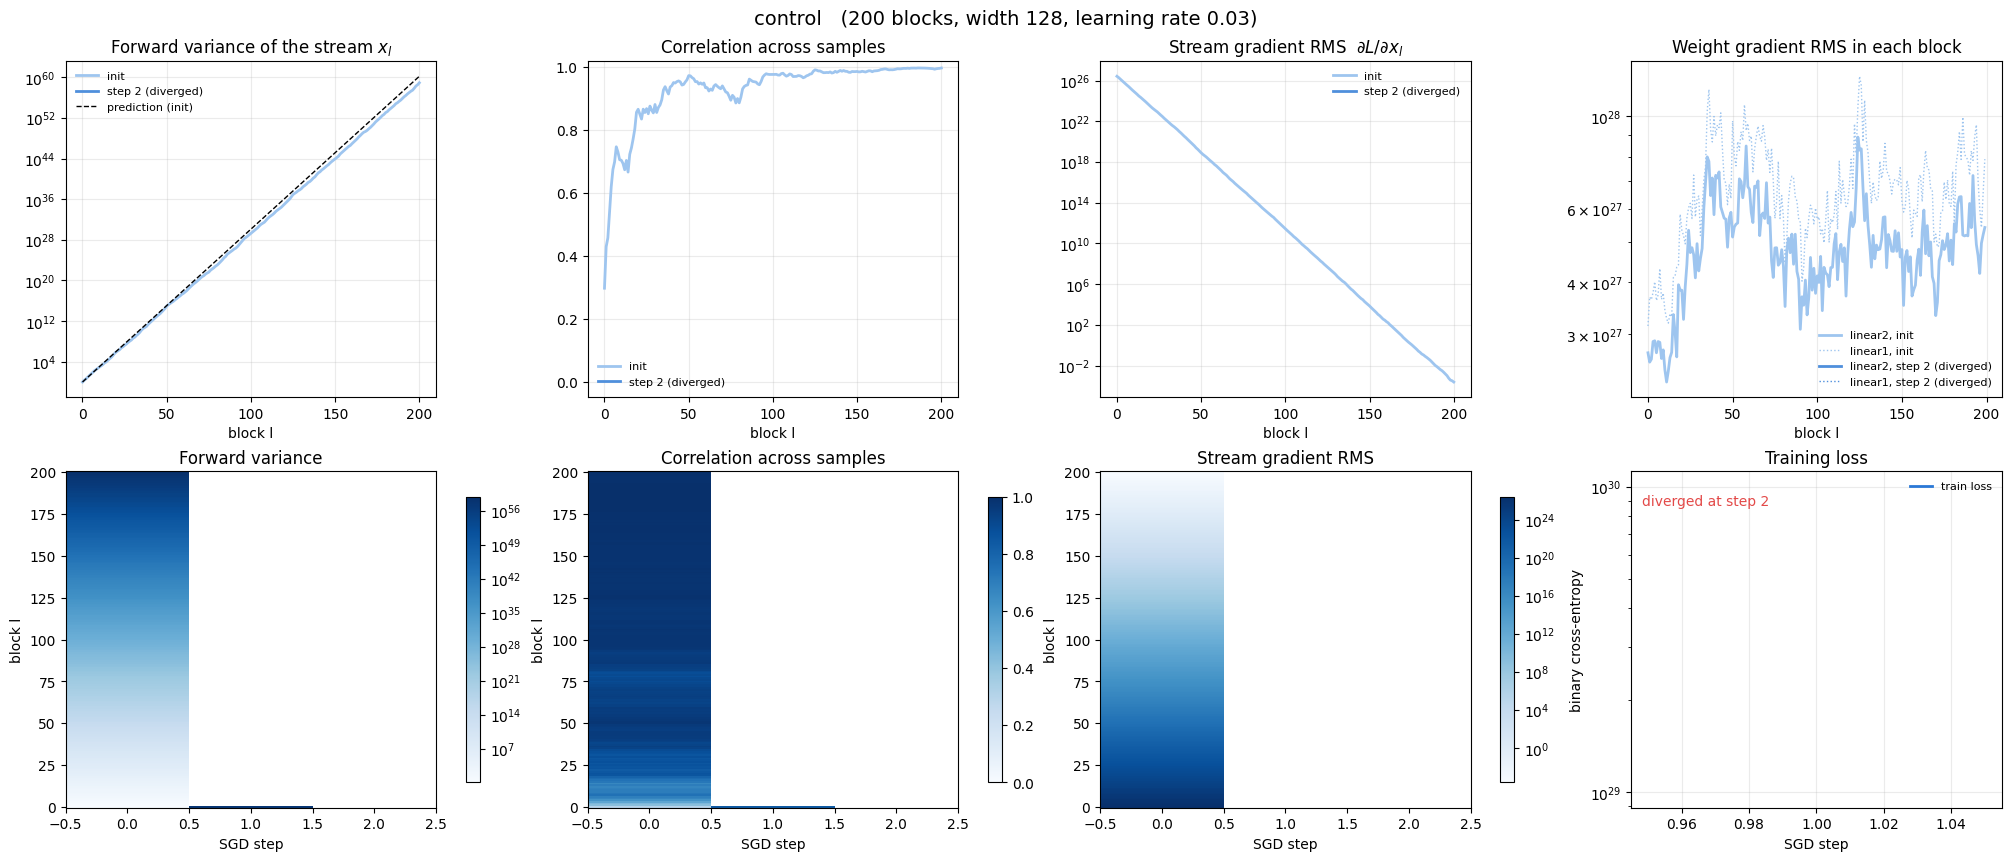

In [ ]:
plot_network("control")

### `batchnorm`

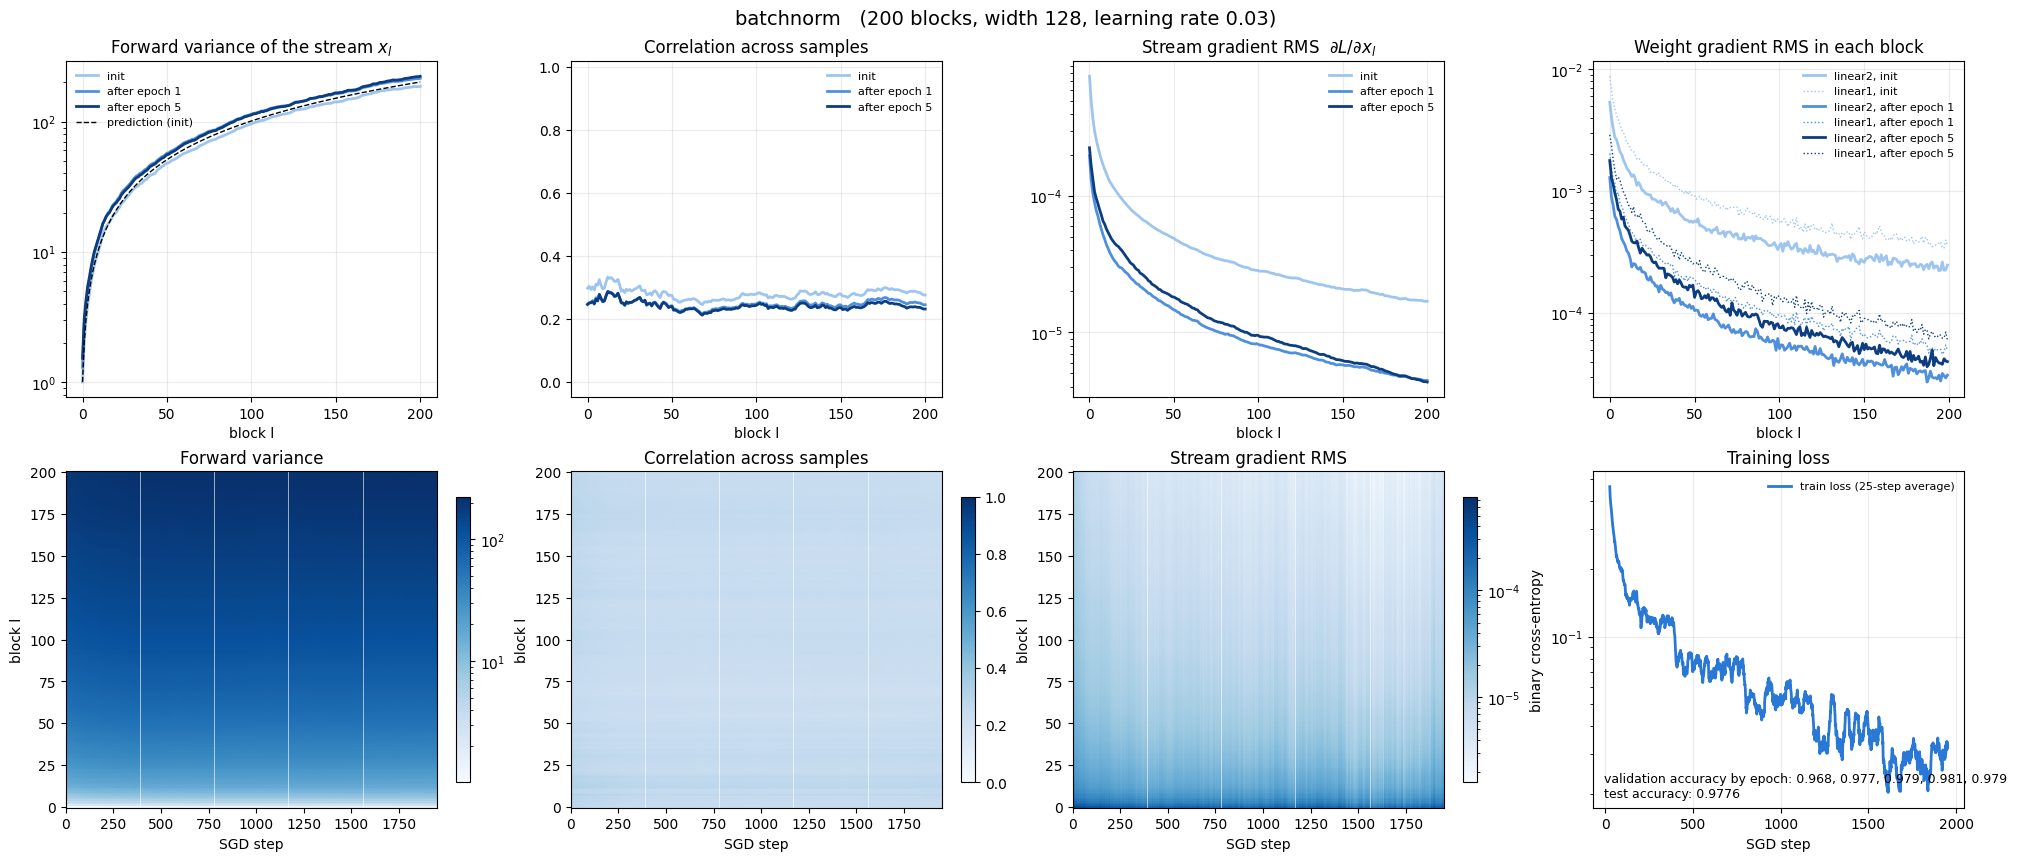

In [ ]:
plot_network("batchnorm")

### `layernorm`

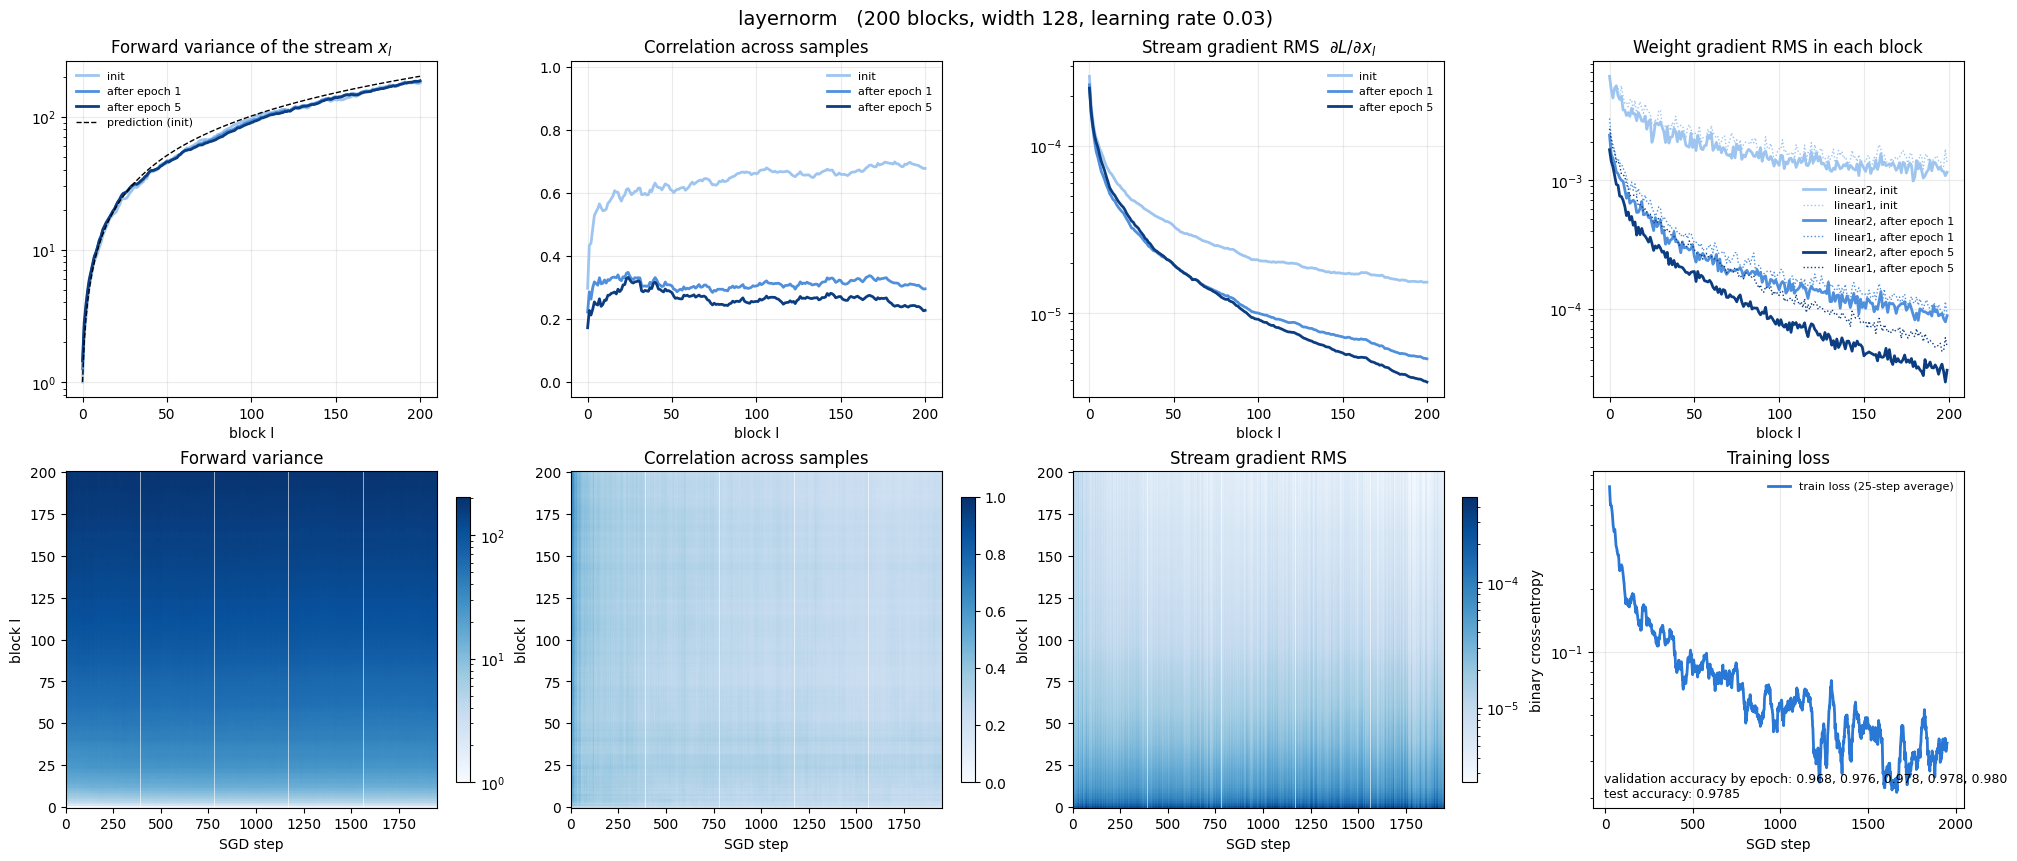

In [ ]:
plot_network("layernorm")

### `scaled`

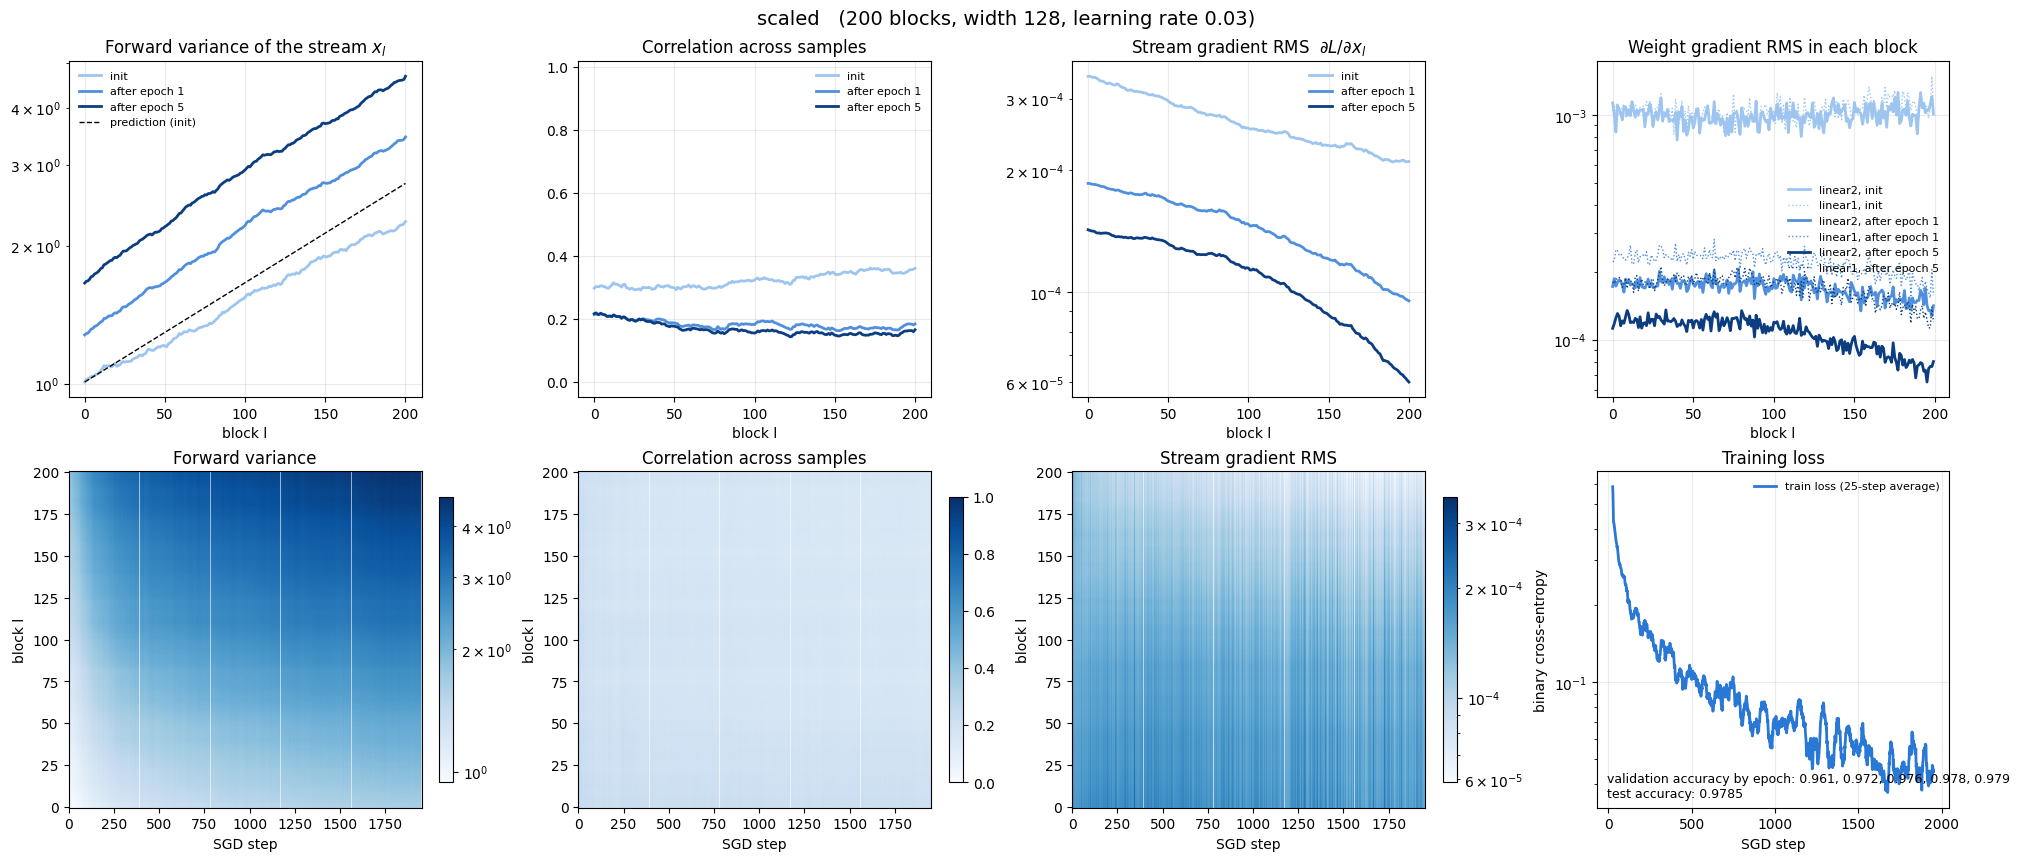

In [ ]:
plot_network("scaled")

## 11. Comparison across networks

The same three measures with every network on one set of axes: at initialization (top) and after training (bottom). Dashed lines on the top-left panel are the predictions from section 4.

In [ ]:
NETWORK_COLORS = {"control": "#8a8983", "batchnorm": "#2a78d6", "layernorm": "#eb6834", "scaled": "#1baf7a"}
depths = np.arange(NUM_BLOCKS + 1)

figure, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
for panel_row, (when, row) in enumerate([("at initialization", 0), ("after training", -1)]):
    for name, result in results.items():
        color = NETWORK_COLORS[name]
        label = name
        if panel_row == 1 and result["diverged_at_step"] is not None:
            label += " (diverged)"
        plot_profile(axes[panel_row, 0], depths, result["stream_variance"][row], color, label, True, linewidth=2)
        plot_profile(axes[panel_row, 1], depths, result["sample_correlation"][row], color, label, False, linewidth=2)
        plot_profile(axes[panel_row, 2], depths, result["stream_grad_rms"][row], color, label, True, linewidth=2)
        if panel_row == 0:
            axes[0, 0].plot(depths, predicted_stream_variance(name, result["stream_variance"][0][0]),
                            color=color, linewidth=1, linestyle="--")
    axes[panel_row, 0].set(title=f"Forward variance, {when}", xlabel="block l", yscale="log")
    axes[panel_row, 1].set(title=f"Correlation across samples, {when}", xlabel="block l", ylim=(-0.05, 1.02))
    axes[panel_row, 2].set(title=f"Stream gradient RMS, {when}", xlabel="block l", yscale="log")
    for axis in axes[panel_row]:
        axis.grid(alpha=0.25)
        axis.legend(fontsize=8, frameon=False)
plt.show()

### Validation accuracy against the baselines

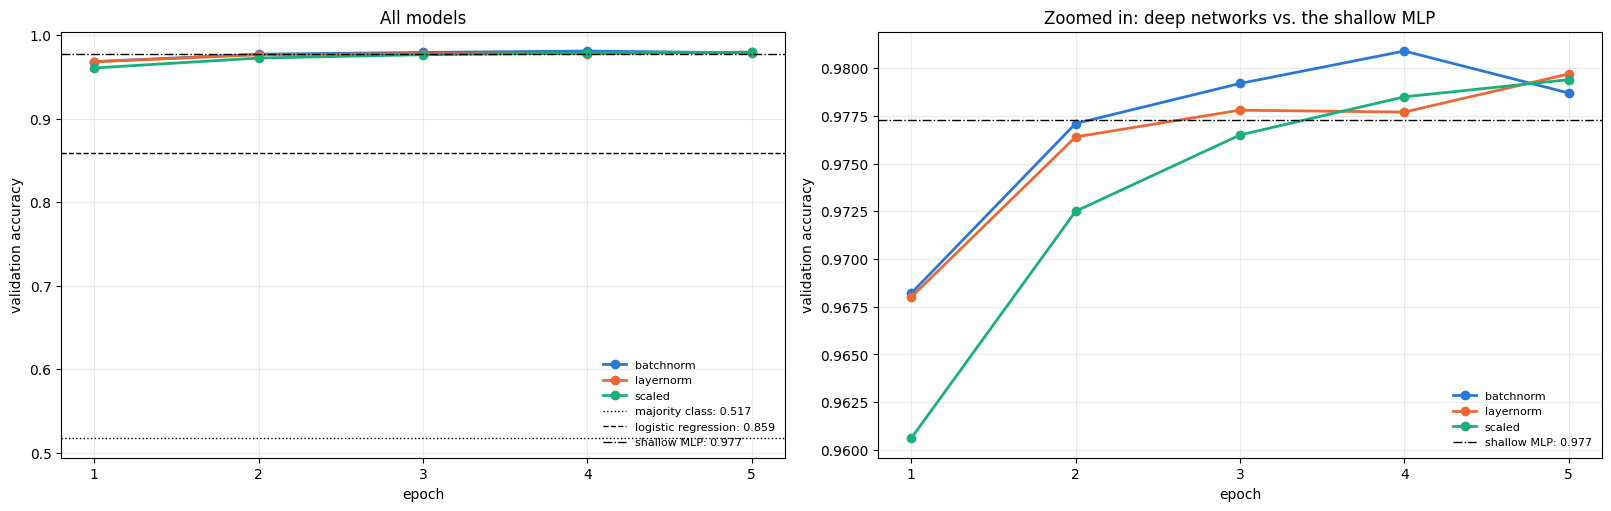

In [ ]:
BASELINE_LINE_STYLES = {"majority class": ":", "logistic regression": "--", "shallow MLP": "-."}

figure, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)
for axis, zoomed in zip(axes, [False, True]):
    for name, result in results.items():
        if result["validation_accuracy"]:
            epochs = np.arange(1, len(result["validation_accuracy"]) + 1)
            axis.plot(epochs, result["validation_accuracy"], "o-", color=NETWORK_COLORS[name],
                      linewidth=2, label=name)
    for baseline_name, (val_acc, _) in baselines.items():
        if zoomed and val_acc < 0.9:
            continue   # the zoomed view only shows the baselines near the deep networks
        axis.axhline(val_acc, color="black", linewidth=1, linestyle=BASELINE_LINE_STYLES[baseline_name],
                     label=f"{baseline_name}: {val_acc:.3f}")
    axis.set(xlabel="epoch", ylabel="validation accuracy", xticks=range(1, NUM_EPOCHS + 1),
             title="Zoomed in: deep networks vs. the shallow MLP" if zoomed else "All models")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8, frameon=False, loc="lower right")
plt.show()